# 04 Clustering: a typology of Russian monotowns

**Goal:** group monotowns into types by their demographic and economic trajectory, then see where Slantsy (item 109 in Order 469-р) fits.

**Data:** `data/processed/features.csv` from notebook 03: 247 monotowns. Only towns with all five clustering variables are clustered; missing values are not imputed.

**Clustering variables**

| variable | meaning | years |
|---|---|---|
| `pop_change_23_25` | population change, % | 2023 to 2025 |
| `net_mig_per_1000` | average yearly net migration per 1,000 residents | 2021-2023 |
| `wage_rel` | average wage relative to the regional median of districts and okrugs | 2025 |
| `jobs_per_1000` | employees of large and medium organisations per 1,000 residents | 2025 |
| `job_change_pct` | change in the number of those employees, % | 2017 to 2025 |

The industry share (mining + manufacturing) is not used to build clusters: Rosstat hides the data of dominant employers for confidentiality, so it is only a lower bound. It is used later to describe the clusters.

In [2]:


import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler, RobustScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 40)

In [3]:
# oktmo codes stay text (some start with 0)
features = pd.read_csv(
    "../data/processed/features.csv",
    dtype={"oktmo": str, "wage_key": str},
)

POP_OLD, POP_NEW = "pop_change_pct", "pop_change_23_25"
OTHER_VARS = ["net_mig_per_1000", "wage_rel", "jobs_per_1000", "job_change_pct"]
SLANTSY = 109

print("All monotowns:", features.shape)

All monotowns: (247, 36)


In [4]:
# population change 2023-2025 replaces 2017-2025
CLUSTER_VARS = [POP_NEW] + OTHER_VARS
df = features.dropna(subset=CLUSTER_VARS).copy().reset_index(drop=True)
print("In clustering:", len(df))

# which towns entered or left compared with the old selection from notebook 03
old, new = set(features.loc[features["in_clustering"], "number"]), set(df["number"])
print("Added:  ", features.loc[features["number"].isin(new - old), ["number", "name_en"]].values.tolist())
print("Dropped:", features.loc[features["number"].isin(old - new), ["number", "name_en"]].values.tolist())

df.loc[df["number"] == SLANTSY, ["number", "name_en", "region_en", "category"] + CLUSTER_VARS]

In clustering: 232
Added:   [[9, 'Petrovsk-Zabaykalsky'], [76, 'Verkh-Usugli'], [77, 'Krasnokamensk'], [78, 'Aginskoye'], [79, 'Borzya']]
Dropped: [[243, 'Kasimov']]


,number,name_en,region_en,category,pop_change_23_25,net_mig_per_1000,wage_rel,jobs_per_1000,job_change_pct
95,109,Slantsy,Leningrad Oblast,2,-3.207783,3.54558,0.990582,138.700823,-0.55756


In [5]:
df[CLUSTER_VARS].describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
pop_change_23_25,232.0,-1.88,1.34,-6.29,-2.66,-1.89,-1.23,4.55
net_mig_per_1000,232.0,-1.57,6.22,-30.03,-4.85,-1.42,1.46,34.72
wage_rel,232.0,1.14,0.25,0.70,0.99,1.08,1.25,2.85
jobs_per_1000,232.0,236.34,92.77,61.38,171.52,218.21,268.39,618.30
job_change_pct,232.0,-5.34,18.67,-42.42,-14.56,-8.67,-0.65,101.83


## Choosing the population variable

The 2021 census reset Rosstat's population estimates, so population change 2017-2025 mixes real change with the census correction (see notebook 03). Population change 2023-2025 is shorter but on one census basis. As a check, both are compared with net migration, which comes from registrations and is not affected by the census reset.

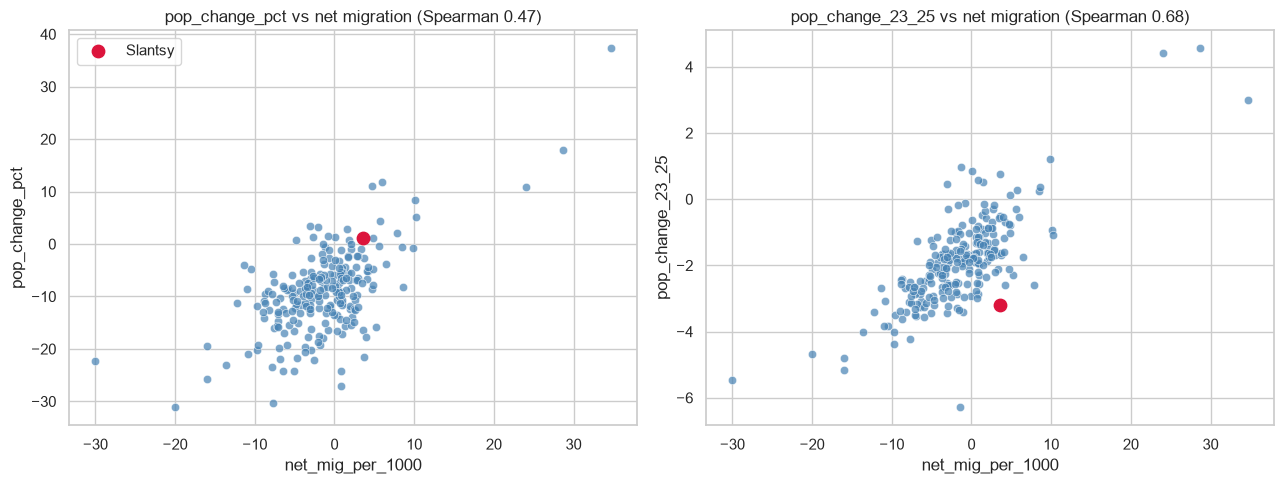

Towns with each variable: 234 vs 239


In [6]:
both = features.dropna(subset=[POP_OLD, POP_NEW, "net_mig_per_1000"])
slantsy = both[both["number"] == SLANTSY]

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, var in zip(axes, [POP_OLD, POP_NEW]):
    sns.scatterplot(data=both, x="net_mig_per_1000", y=var, ax=ax, color="steelblue", alpha=0.7)
    ax.scatter(slantsy["net_mig_per_1000"], slantsy[var], color="crimson", s=80, label="Slantsy")
    rho = both[var].corr(both["net_mig_per_1000"], method="spearman")
    ax.set_title(f"{var} vs net migration (Spearman {rho:.2f})")
axes[0].legend()
plt.tight_layout()
plt.show()

print("Towns with each variable:", features[POP_OLD].notna().sum(), "vs", features[POP_NEW].notna().sum())

## Distributions and outliers

K-means groups towns by distance, so it is sensitive to scale and to extreme values. Before scaling, we check how each variable is distributed, which towns are extreme, and whether any two variables measure nearly the same thing (strongly correlated variables would count twice in the distance).

An outlier here is a town more than 3 standard deviations from the mean (|z| > 3).

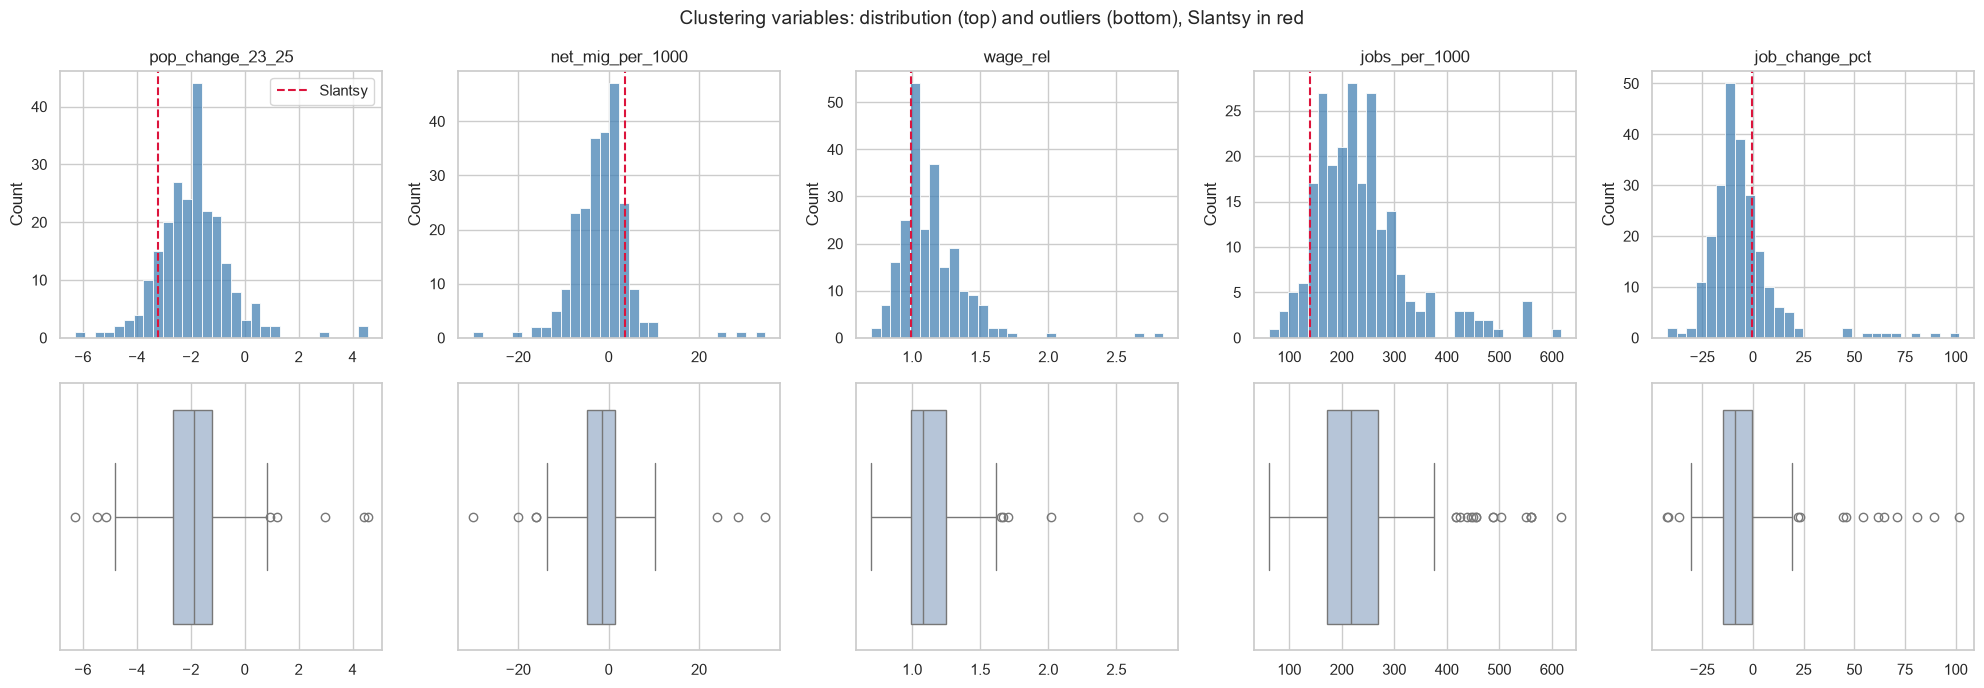

In [7]:
fig, axes = plt.subplots(2, 5, figsize=(20, 7))

for i, var in enumerate(CLUSTER_VARS):
    sns.histplot(df[var], bins=30, ax=axes[0, i], color="steelblue")
    axes[0, i].axvline(df.loc[df["number"] == SLANTSY, var].iloc[0],
                       color="crimson", linestyle="--", label="Slantsy")
    axes[0, i].set_title(var)
    axes[0, i].set_xlabel("")
    sns.boxplot(x=df[var], ax=axes[1, i], color="lightsteelblue")
    axes[1, i].set_xlabel("")

axes[0, 0].legend()
plt.suptitle("Clustering variables: distribution (top) and outliers (bottom), Slantsy in red",
             fontsize=14)
plt.tight_layout()
plt.show()

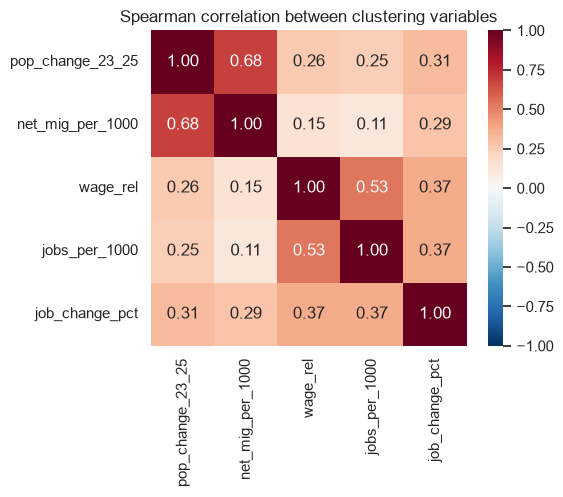

In [8]:
corr = df[CLUSTER_VARS].corr(method="spearman")

plt.figure(figsize=(6, 5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1, square=True)
plt.title("Spearman correlation between clustering variables")
plt.tight_layout()
plt.show()

In [9]:
# |z| > 3 on any variable
z = (df[CLUSTER_VARS] - df[CLUSTER_VARS].mean()) / df[CLUSTER_VARS].std()
outlier_mask = (z.abs() > 3).any(axis=1)

outliers = df.loc[outlier_mask, ["number", "name_en", "region_en"] + CLUSTER_VARS].copy()
outliers["extreme_on"] = z[outlier_mask].apply(
    lambda row: ", ".join(row.index[row.abs() > 3]), axis=1)

print("Towns with |z| > 3:", outlier_mask.sum())
outliers.round(2).sort_values("extreme_on")

Towns with |z| > 3: 15


,number,name_en,region_en,pop_change_23_25,net_mig_per_1000,wage_rel,jobs_per_1000,job_change_pct,extreme_on
155,181,Aleksin,Tula Oblast,-2.34,1.76,1.13,437.81,101.83,job_change_pct
211,241,Zelenodolsk,Republic of Tatarstan,-0.29,5.54,0.87,341.21,64.66,job_change_pct
223,255,Kotovsk,Tambov Oblast,-1.74,2.40,1.18,456.60,89.56,job_change_pct
99,113,Kirovsk,Murmansk Oblast,-1.89,-5.20,1.43,618.30,18.63,jobs_per_1000
131,155,Aykhal,Sakha Republic (Yakutia),0.96,-1.29,1.34,561.32,9.66,jobs_per_1000
132,156,Mirny,Sakha Republic (Yakutia),0.84,0.04,1.34,561.32,9.66,jobs_per_1000
129,153,Neryungri,Sakha Republic (Yakutia),-0.30,2.64,1.30,550.82,61.92,"jobs_per_1000, job_change_pct"
101,115,Nikel,Murmansk Oblast,-5.47,-30.03,0.99,302.86,-20.92,net_mig_per_1000
33,44,Skopin,Ryazan Oblast,-6.29,-1.41,0.90,188.59,-4.87,pop_change_23_25
148,173,Verkhnyaya Pyshma,Sverdlovsk Oblast,4.43,23.98,1.52,283.46,18.60,"pop_change_23_25, net_mig_per_1000"


## Capping outliers and scaling

The 15 extreme towns are real (defence-industry job growth, northern mining towns, growing suburbs, Nikel after the smelter closure), so they stay in the analysis. To stop them from pulling cluster centres, each variable is capped at its 2nd and 98th percentile (winsorizing): values beyond these limits are set to the limit. The original values are kept for describing the clusters.

The variables are then standardised (mean 0, standard deviation 1), because k-means measures distance and would otherwise be dominated by the variable with the largest numbers (jobs per 1,000).

In [10]:
# cap each variable at its 2nd and 98th percentile; df keeps the original values
lower = df[CLUSTER_VARS].quantile(0.02)
upper = df[CLUSTER_VARS].quantile(0.98)
X_capped = df[CLUSTER_VARS].clip(lower=lower, upper=upper, axis=1)

print("Towns capped per variable:")
print(((df[CLUSTER_VARS] < lower) | (df[CLUSTER_VARS] > upper)).sum(), "\n")

# standardise: each variable gets mean 0 and standard deviation 1
X = StandardScaler().fit_transform(X_capped)
pd.DataFrame(X, columns=CLUSTER_VARS).describe().T.round(2)

Towns capped per variable:
pop_change_23_25    10
net_mig_per_1000    10
wage_rel            10
jobs_per_1000       10
job_change_pct      10
dtype: int64 



,count,mean,std,min,25%,50%,75%,max
pop_change_23_25,232.0,-0.0,1.0,-2.26,-0.65,0.02,0.59,2.42
net_mig_per_1000,232.0,0.0,1.0,-2.39,-0.65,0.06,0.65,2.41
wage_rel,232.0,-0.0,1.0,-1.66,-0.68,-0.23,0.59,2.67
jobs_per_1000,232.0,-0.0,1.0,-1.53,-0.72,-0.20,0.37,3.24
job_change_pct,232.0,0.0,1.0,-1.38,-0.55,-0.19,0.30,4.16
